# Connecting to OpenAI 

In [1]:
# imports

import os
from dotenv import load_dotenv
from openai import OpenAI




The next cell is where we load in the environment variables in your `.env` file and connect to OpenAI.  



In [4]:
# Load environment variables in a file called .env

load_dotenv(override=True)
api_key = os.getenv('OPENAI_API_KEY')

# Check the key

if not api_key:
    print("No API key was found - please head over to the troubleshooting notebook in this folder to identify & fix!")
elif not api_key.startswith("sk-proj-"):
    print("An API key was found, but it doesn't start sk-proj-; please check you're using the right key - see troubleshooting notebook")
elif api_key.strip() != api_key:
    print("An API key was found, but it looks like it might have space or tab characters at the start or end - please remove them - see troubleshooting notebook")
else:
    print("API key found and looks good so far!")


API key found and looks good so far!


# 1. Zero-Shot Prompting

https://www.kaggle.com/whitepaper-prompt-engineering

13page

In [5]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "You are a sentiment classifier.\n"
                "Classify the given movie review as exactly one word:\n"
                "POSITIVE, NEUTRAL, or NEGATIVE.\n"
                "Respond with only that one word, nothing else."
            ),
        },
        {
            "role": "user",
            "content": (
                '"Her" is a disturbing study revealing the direction\n'
                "humanity is headed if AI is allowed to keep evolving,\n"
                "unchecked. I wish there were more movies like this masterpiece."
            ),
        },
    ],
    temperature=0.1,
    max_tokens=5,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

POSITIVE


In [7]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "당신은 감성 분류기입니다.\n"
                "주어진 영화 리뷰를 정확히 한 단어로 분류하세요:\n"
                "긍정, 중립, 부정 중 하나만 답하세요.\n"
                "다른 말은 절대 하지 마세요."
            ),
        },
        {
            "role": "user",
            "content": (
                '"그녀(Her)"는 AI가 계속 진화하도록 내버려 뒀을 때\n'
                "인류가 향하게 될 방향을 섬뜩하게 보여주는 영화다.\n"
                "이런 걸작이 더 많이 나왔으면 좋겠다."
            ),
        },
    ],
    temperature=0.1,
    max_tokens=5,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)
# 출력: 긍정

긍정


In [9]:
from openai import OpenAI

# OpenAI 클라이언트 생성
client = OpenAI()

# Zero-Shot Prompting 예제
# 예시 없이 바로 질문하는 방식

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 친절한 여행 가이드입니다."
        },
        {
            "role": "user",
            "content": "서울의 대표 관광지 3곳을 추천해주세요."
        }
    ],
    temperature=0.8,
    max_completion_tokens=300
)

# 응답 출력
print("=== Zero-Shot Prompting Example ===")
print(response.choices[0].message.content)

=== Zero-Shot Prompting Example ===
물론입니다! 서울의 대표 관광지 3곳을 추천해드릴게요.

1. 경복궁  
조선 시대의 대표 궁궐로, 아름다운 건축물과 전통 정원을 감상할 수 있습니다. 한복 체험도 가능해 한국 전통문화를 직접 느껴보기에 좋아요.

2. N서울타워 (남산타워)  
서울의 랜드마크 중 하나로, 전망대에서 서울 전경을 한눈에 볼 수 있습니다. 특히 야경이 아름다워 연인들의 데이트 명소로도 유명합니다.

3. 명동  
서울의 대표 쇼핑 거리로, 다양한 패션 브랜드와 맛집, 카페가 즐비해 있습니다. 활기찬 분위기 속에서 쇼핑과 길거리 음식을 즐길 수 있어요.

서울 여행을 즐겁게 하시길 바랍니다! 더 궁금한 점 있으시면 말씀해 주세요.


# 2. One-Shot Prompting

In [12]:
from openai import OpenAI

# OpenAI 클라이언트 생성
client = OpenAI()

# One-Shot Prompting 예제
# 하나의 예시를 먼저 제공한 뒤 새로운 질문 수행

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 친절한 여행 가이드입니다."
        },
        {
            "role": "user",
            "content": """
예시:
질문: 부산의 대표 관광지 2곳을 추천해주세요.
답변:
1. 해운대
부산을 대표하는 해수욕장으로 아름다운 바다 경치를 볼 수 있습니다.

2. 감천문화마을
형형색색의 건물과 예술 작품으로 유명한 관광지입니다.

이제 질문:
서울의 대표 관광지 2곳을 추천해주세요.
"""
        }
    ],
    temperature=0.8,
    max_completion_tokens=300
)

# 응답 출력
print("=== One-Shot Prompting Example ===")
print(response.choices[0].message.content)

=== One-Shot Prompting Example ===
1. 경복궁  
조선 시대의 대표 궁궐로, 전통 건축물과 아름다운 정원을 감상할 수 있습니다.

2. 남산서울타워  
서울의 랜드마크로, 도시 전경을 한눈에 볼 수 있는 전망대와 다양한 즐길 거리가 있습니다.


In [3]:
from openai import OpenAI

# OpenAI 클라이언트 생성
client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 친절한 음식 추천 전문가입니다."
        },
        {
            "role": "user",
            "content": """
예시:
질문: 일본 음식 추천해주세요.
답변:
1. 초밥
신선한 생선을 사용하는 대표 일본 음식입니다.

2. 라멘
진한 국물과 면이 특징인 인기 음식입니다.

이제 질문:
한국 음식 추천해주세요.
"""
        }
    ],
    temperature=0.7,
    max_completion_tokens=300
)

print(response.choices[0].message.content)

1. 비빔밥  
다양한 나물과 고기, 고추장을 밥과 함께 비벼 먹는 건강한 한 그릇 음식입니다.

2. 불고기  
얇게 썬 소고기를 달콤한 양념에 재워 구워 먹는 대표적인 한국식 바비큐입니다.

3. 김치찌개  
매콤한 김치와 돼지고기, 두부 등을 넣어 끓인 국물 요리로 한국인의 밥상에 빠지지 않는 찌개입니다.


#   3. Few-Shot Prompting

https://www.kaggle.com/whitepaper-prompt-engineering

15 Page

In [4]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": "Parse a customer's pizza order into valid JSON.\nRespond with only the JSON object, no explanation.",
        },
        # --- few-shot 예시 1 ---
        {
            "role": "user",
            "content": "I want a small pizza with cheese, tomato sauce, and pepperoni.",
        },
        {
            "role": "assistant",
            "content": '{"size": "small", "type": "normal", "ingredients": [["cheese", "tomato sauce", "pepperoni"]]}',
        },
        # --- few-shot 예시 2 ---
        {
            "role": "user",
            "content": "Can I get a large pizza with tomato sauce, basil and mozzarella?",
        },
        {
            "role": "assistant",
            "content": '{"size": "large", "type": "normal", "ingredients": [["tomato sauce", "basil", "mozzarella"]]}',
        },
        # --- 실제 요청 ---
        {
            "role": "user",
            "content": (
                "Now, I would like a large pizza, with the first half cheese and mozzarella. "
                "And the other tomato sauce, ham and pineapple."
            ),
        },
    ],
    temperature=0.1,
    max_tokens=250,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

{"size": "large", "type": "half-and-half", "ingredients": [["cheese", "mozzarella"], ["tomato sauce", "ham", "pineapple"]]}


In [5]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": "고객의 피자 주문을 유효한 JSON 형식으로 파싱하세요.\nJSON 객체만 응답하고, 다른 설명은 하지 마세요.",
        },
        # --- few-shot 예시 1 ---
        {
            "role": "user",
            "content": "치즈, 토마토 소스, 페퍼로니를 넣은 스몰 피자 주세요.",
        },
        {
            "role": "assistant",
            "content": '{"size": "small", "type": "normal", "ingredients": [["cheese", "tomato sauce", "pepperoni"]]}',
        },
        # --- few-shot 예시 2 ---
        {
            "role": "user",
            "content": "토마토 소스, 바질, 모짜렐라 넣은 라지 피자 한 판 주문할게요.",
        },
        {
            "role": "assistant",
            "content": '{"size": "large", "type": "normal", "ingredients": [["tomato sauce", "basil", "mozzarella"]]}',
        },
        # --- 실제 요청 ---
        {
            "role": "user",
            "content": (
                "라지 피자로 주문하고 싶은데요, "
                "한쪽 절반은 치즈와 모짜렐라, "
                "나머지 절반은 토마토 소스, 햄, 파인애플로 해주세요."
            ),
        },
    ],
    temperature=0.1,
    max_tokens=250,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

{"size": "large", "type": "normal", "ingredients": [["cheese", "mozzarella"], ["tomato sauce", "ham", "pineapple"]]}


https://cloud.google.com/discover/what-is-prompt-engineering#use-cases-and-examples-of-prompt-engineering


## 원하는 입력-출력 쌍의 몇 가지 예시 제공

In [6]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": "동물 이름을 입력받으면 그 동물의 특징을 한 문장으로 설명하세요.",
        },
        # --- few-shot 예시 1 ---
        {
            "role": "user",
            "content": "고양이",
        },
        {
            "role": "assistant",
            "content": "수염과 털이 있는 작은 포유류",
        },
        # --- few-shot 예시 2 ---
        {
            "role": "user",
            "content": "개",
        },
        {
            "role": "assistant",
            "content": "충성도로 유명한 애완견",
        },
        # --- 실제 요청 ---
        {
            "role": "user",
            "content": "코끼리",
        },
    ],
    temperature=0.7,
    max_tokens=50,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)
# 출력: 긴 코와 큰 귀를 가진 육지에서 가장 큰 동물

거대한 몸집과 긴 코, 그리고 뛰어난 기억력을 가진 육상 포유류입니다.


## 원하는 스타일이나 어조 보여주기

In [7]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "당신은 창의적인 글쓰기 도우미입니다.\n"
                "주어진 주제에 대해 예시와 같은 스타일과 어조로 문장을 작성하세요."
            ),
        },
        # --- few-shot 예시 1 (유머 어조) ---
        {
            "role": "user",
            "content": "정치인의 말투가 너무 지루해서 불면증을 치료할 수 있었습니다.",
        },
        {
            "role": "assistant",
            "content": "맞아요, 그 연설은 수면제보다 효과가 좋더라고요. 약국이 망할 판이에요.",
        },
        # --- few-shot 예시 2 (격식 어조) ---
        {
            "role": "user",
            "content": "고위 인사가 유익하고 호감이 가는 연설을 했습니다.",
        },
        {
            "role": "assistant",
            "content": (
                "해당 고위 인사의 연설은 청중에게 깊은 통찰과 긍정적인 인상을 남겼으며, "
                "향후 정책 논의에 있어 중요한 지표가 될 것으로 평가됩니다."
            ),
        },
        # --- 실제 요청 ---
        {
            "role": "user",
            "content": "코미디언의 단독 코미디 연기를 설명하는 문장을 작성해 주세요.",
        },
    ],
    temperature=0.7,
    max_tokens=150,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)
# 출력: 그 코미디언의 단독 공연은 관객의 배꼽을 완전히 강탈해 갔고,
#       귀가 후에도 실실 웃음이 멈추지 않는 부작용을 남겼습니다.

코미디언은 무대 위에서 관객의 가슴 속 깊은 곳에서 터져 나오는 웃음을 이끌어내기 위해 기발한 재치와 유머로 가득 찬 이야기를 풀어놓습니다. 그의 몸짓과 표정은 상황을 더욱 생동감 있게 만들고, 관객들은 그가 전하는 일상의 소소한 문제들을 유머러스하게 해석하는 데 공감하며 함께 웃음을 나누게 됩니다. 매 순간의 타이밍과 농담의 전달력이 어우러져, 그 코미디언의 연기는 단순한 웃음이 아닌, 삶의 작은 희망을 전하는 특별한 경험이 됩니다.


## 원하는 세부정보 수준 표시

In [9]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "당신은 소설 줄거리 요약 도우미입니다.\n"
                "예시와 동일한 수준의 세부정보로 줄거리를 요약하세요."
            ),
        },
        # --- few-shot 예시 1 (간략 수준) ---
        {
            "role": "user",
            "content": "E.T.의 줄거리를 요약해 주세요.",
        },
        {
            "role": "assistant",
            "content": "이 영화는 외계인과 친구가 된 어린 소년에 관한 내용이었습니다.",
        },
        # --- few-shot 예시 2 (상세 수준) ---
        {
            "role": "user",
            "content": "E.T.의 줄거리를 자세히 요약해 주세요.",
        },
        {
            "role": "assistant",
            "content": (
                "이 공상과학 영화는 외로운 소년 엘리엇의 이야기입니다. "
                "엘리엇은 지구에 착초된 외계인과 독특한 유대 관계를 발견하고 형성합니다. "
                "둘은 깊은 우정을 나누지만, 정부 요원들이 외계인을 쫓자 "
                "엘리엇은 친구를 고향 별로 돌려보내기 위해 위험을 무릅씁니다."
            ),
        },
        # --- 실제 요청 (상세 예시 직후 → 상세 수준으로 응답) ---
        {
            "role": "user",
            "content": " 소설 한강의 줄거리를 요약해 주세요.",
        },
    ],
    temperature=0.4,
    max_tokens=200,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

한강은 한국의 현대사를 배경으로 한 소설로, 주로 1980년대 광주 민주화 운동을 중심으로 전개됩니다. 이야기는 여러 인물의 시점을 통해 진행되며, 이들은 각기 다른 배경과 경험을 가지고 있습니다. 주인공은 가족과 친구를 잃은 상처를 안고 있으며, 그들의 고통과 회복의 과정을 통해 사회의 아픔을 드러냅니다. 소설은 개인의 삶과 역사적 사건이 얽히는 복잡한 관계를 탐구하며, 기억과 상실, 그리고 치유의 과정을 깊이 있게 다룹니다. 한강은 인간의 고통과 연대의 의미를 성찰하며, 독자에게 강렬한 감정을 불러일으킵니다.


#  4. Chain-of-Thought Prompting(CoT)

https://www.kaggle.com/whitepaper-prompt-engineering    30 page


In [11]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                "When I was 3 years old, my partner was 3 times my age. "
                "Now, I am 20 years old. How old is my partner? "
                "Let's think step by step."
            ),
        }
    ],
    temperature=0,
    max_tokens=512,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

Let's break it down step by step.

1. When you were 3 years old, your partner was 3 times your age. So, at that time:
   \[
   \text{Your age} = 3 \text{ years}
   \]
   \[
   \text{Partner's age} = 3 \times 3 = 9 \text{ years}
   \]

2. The age difference between you and your partner is:
   \[
   \text{Age difference} = \text{Partner's age} - \text{Your age} = 9 - 3 = 6 \text{ years}
   \]

3. Now, you are 20 years old. To find your partner's current age, we add the age difference to your current age:
   \[
   \text{Partner's current age} = \text{Your current age} + \text{Age difference} = 20 + 6 = 26 \text{ years}
   \]

So, your partner is currently **26 years old**.


In [15]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                "내가 3살이었을 때, 내 파트너의 나이는 내 나이의 3배였습니다. "
                "지금 나는 20살입니다. 내 파트너는 몇 살인가요? "
                "단계적으로 생각해봅시다."
            ),
        }
    ],
    temperature=0,
    max_tokens=512,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

문제를 단계적으로 해결해봅시다.

1. **현재 나이**: 당신의 현재 나이는 20살입니다.

2. **과거의 나이**: 당신이 3살이었을 때, 그때의 나이를 계산해봅시다. 현재 나이에서 3을 빼면:
   \[
   20 - 3 = 17
   \]
   즉, 당신이 3살이었을 때는 17년 전입니다.

3. **파트너의 나이**: 당신이 3살이었을 때, 파트너의 나이는 당신 나이의 3배였습니다. 당신이 3살이었을 때 파트너의 나이는:
   \[
   3 \times 3 = 9 \text{살}
   \]

4. **파트너의 현재 나이**: 이제 파트너의 나이를 계산해봅시다. 17년이 지났으므로, 파트너의 현재 나이는:
   \[
   9 + 17 = 26 \text{살}
   \]

결론적으로, 당신의 파트너는 현재 26살입니다.


https://cloud.google.com/discover/what-is-prompt-engineering#use-cases-and-examples-of-prompt-engineering


단계별 추론 장려

In [14]:
import openai

client = openai.OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 수학 문제를 단계별로 풀어주는 선생님입니다."
        },
        {
            "role": "user",
            "content": """이 문제를 단계별로 풀어보세요.철수는 사과 5개를 갖고 있었고 2개를 먹었습니다. 사과가 몇 개나 남았나요?"""
        }
    ]
)

print(response.choices[0].message.content)

이 문제를 단계별로 풀어보겠습니다.

1. **사과의 초기 개수 확인**: 철수는 처음에 사과 5개를 가지고 있습니다.
   
   초기 사과 개수 = 5개

2. **소비한 사과 개수 확인**: 철수는 2개의 사과를 먹었습니다.

   소비한 사과 개수 = 2개

3. **남은 사과 개수 계산**: 남은 사과의 개수를 계산하기 위해 초기 개수에서 소비한 개수를 빼줍니다.

   남은 사과 개수 = 초기 사과 개수 - 소비한 사과 개수  
   남은 사과 개수 = 5개 - 2개 = 3개

4. **결과 확인**: 철수가 남은 사과는 3개입니다.

따라서, 철수는 사과가 3개 남았습니다.


In [17]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                "영화 ET 평론의 감상을 결정하는 데 당신의 생각이 진행된 과정을 설명해 주세요. "
                "'연기는 멋있었지만 예상할 수 있는 줄거리였습니다.'"
            ),
        }
    ],
    temperature=0,
    max_tokens=512,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

영화 "E.T. the Extra-Terrestrial"에 대한 평론을 작성할 때, 여러 요소를 고려하여 감상을 결정하는 과정을 설명하겠습니다.

1. **연기**: 영화에서의 연기는 매우 중요한 요소입니다. 헨리 토마스(엘리엇 역)와 드류 배리모어(갤리 역)의 연기는 특히 인상적입니다. 그들의 감정 표현과 캐릭터에 대한 몰입은 관객이 이야기에 더욱 깊이 빠져들게 만듭니다. 연기가 뛰어난 만큼, 캐릭터의 감정선이 잘 전달되어 관객이 공감할 수 있는 부분이 많습니다.

2. **줄거리**: "E.T."의 줄거리는 외계인과 어린 소년의 우정을 중심으로 전개됩니다. 이 점에서 예상할 수 있는 전개가 많습니다. 외계인이 지구에 불시착하고, 이를 숨기려는 엘리엇과 그의 친구들이 겪는 모험은 전형적인 이야기 구조를 따릅니다. 이러한 점은 관객에게 익숙하게 느껴질 수 있으며, 예측 가능한 요소가 많아 긴장감이 떨어질 수 있습니다.

3. **주제와 메시지**: 영화는 우정, 가족, 소외감, 그리고 이해와 수용의 중요성을 다룹니다. 이러한 주제는 보편적이어서 많은 관객이 공감할 수 있습니다. 그러나 이러한 메시지가 전개되는 방식이 다소 예측 가능하다는 점은 아쉬움으로 남을 수 있습니다.

4. **비주얼과 음악**: 스티븐 스필버그 감독의 독창적인 비주얼과 존 윌리엄스의 감동적인 음악은 영화의 감정적 깊이를 더합니다. 이러한 요소들은 줄거리의 예측 가능성을 어느 정도 상쇄시키며, 관객에게 강한 인상을 남깁니다.

5. **결론**: 종합적으로 볼 때, "E.T."는 연기가 뛰어나고 감정적으로 깊이 있는 영화이지만, 줄거리의 예측 가능성은 관객에게 다소 아쉬움을 남길 수 있습니다. 그럼에도 불구하고, 영화가 전달하는 메시지와 감정은 여전히 강력하며, 이는 많은 이들에게 오랫동안 기억에 남는 작품으로 자리잡게


사고의 논리적 시퀀스를 통해 모델 유도

In [18]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                "이 이메일을 스팸 또는 스팸이 아닌 것으로 분류하려면 다음 사항을 고려하세요. "
                "1. 발신자가 아는 사람인가요? "
                "2. 제목에 의심스러운 키워드가 포함되어 있나요? "
                "3. 믿기 어려울 정도로 솔깃한 내용을 제안하는 이메일인가요?\n\n"
                "이메일:\n"
                "발신자: unknown@promo-deals.com\n"
                "제목: 🎉 축하합니다! 무료 아이폰 당첨 — 지금 바로 수령하세요!\n"
                "내용: 귀하는 특별 추첨에서 선정되었습니다. "
                "링크를 클릭하여 24시간 내에 경품을 수령하세요."
            ),
        }
    ],
    temperature=0,
    max_tokens=512,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

이 이메일을 스팸으로 분류할 수 있는 몇 가지 이유가 있습니다:

1. **발신자가 아는 사람인가요?**: 발신자가 "unknown@promo-deals.com"으로, 발신자를 알지 못하는 경우입니다. 이는 스팸의 일반적인 특징 중 하나입니다.

2. **제목에 의심스러운 키워드가 포함되어 있나요?**: 제목에 "무료 아이폰 당첨"과 같은 의심스러운 키워드가 포함되어 있습니다. 이러한 표현은 종종 스팸 이메일에서 사용됩니다.

3. **믿기 어려울 정도로 솔깃한 내용을 제안하는 이메일인가요?**: "무료 아이폰"과 같은 제안은 매우 솔깃하지만, 현실적으로 믿기 어려운 내용입니다. 이는 스팸 이메일의 전형적인 특징입니다.

따라서 이 이메일은 스팸으로 분류하는 것이 적절합니다.


# 5. Zero-Shot Chain-of-Thought Prompting

https://www.geeksforgeeks.org/artificial-intelligence/zero-shot-chain-of-thought-prompting/


In [22]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                "If I have 15 oranges and I give away 7 oranges, "
                "how many oranges do I have left? "
                "Let's think step by step."
            ),
        }
    ],
    temperature=0,
    max_tokens=512,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

Sure! Let's break it down step by step:

1. **Start with the total number of oranges**: You have 15 oranges.
2. **Determine how many oranges you give away**: You give away 7 oranges.
3. **Subtract the number of oranges given away from the total**: 

   \[
   15 \text{ oranges} - 7 \text{ oranges} = 8 \text{ oranges}
   \]

So, after giving away 7 oranges, you have 8 oranges left.


In [23]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                "오렌지가 15개 있는데 7개를 나눠줬습니다. "
                "남은 오렌지는 몇 개인가요? "
                "단계적으로 생각해봅시다."
            ),
        }
    ],
    temperature=0,
    max_tokens=512,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

단계적으로 생각해보겠습니다.

1. 처음에 오렌지가 15개 있습니다.
2. 그 중 7개를 나눠주었습니다.
3. 남은 오렌지를 계산하기 위해 15에서 7을 빼면 됩니다.

계산:
15 - 7 = 8

따라서, 남은 오렌지는 8개입니다.


일반 예제

In [24]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 문제 해결 전문가입니다."
        },
        {
            "role": "user",
            "content": """
한 카페에 손님이 하루 평균 120명 방문합니다.
비가 오는 날에는 손님 수가 평균보다 30명 감소합니다.
오늘은 비가 왔고 실제 방문 손님은 95명이었습니다.

오늘 손님 수가 평균과 얼마나 차이 나는지 단계별로 생각해 봅시다.
"""
        }
    ],
    temperature=0.2,
    max_completion_tokens=300
)

print(response.choices[0].message.content)

네, 오늘 손님 수가 평균과 얼마나 차이 나는지 단계별로 생각해 보겠습니다.

1. **평균 손님 수 확인**  
   하루 평균 손님 수는 120명입니다.

2. **비가 오는 날 손님 수 감소량 확인**  
   비가 오는 날에는 손님 수가 평균보다 30명 감소합니다.

3. **비 오는 날 예상 손님 수 계산**  
   평균 손님 수 120명에서 30명을 빼면,  
   예상 손님 수 = 120명 - 30명 = 90명

4. **오늘 실제 방문 손님 수 확인**  
   오늘은 비가 왔고, 실제 방문 손님 수는 95명입니다.

5. **오늘 손님 수와 예상 손님 수 차이 계산**  
   실제 방문 손님 수 95명에서 예상 손님 수 90명을 빼면,  
   차이 = 95명 - 90명 = 5명

6. **오늘 손님 수와 평균 손님 수 차이 계산**  
   실제 방문 손님 수 95명에서 평균 손님 수 120명을 빼면,  
   차이 = 95명 - 120명 = -25명

**결론:**  
- 오늘 손님 수는 비 오는 날 예상 손님 수보다 5명 더 많습니다.  
- 오늘 손님 수


# 6. Contextual Prompting

https://www.kaggle.com/whitepaper-prompt-engineering   65 Page

In [26]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                "Context: You are writing for a blog about retro 80's arcade video games.\n\n"
                "Suggest 3 topics to write an article about with a few lines of description "
                "of what this article should contain."
            ),
        }
    ],
    temperature=1,
    max_tokens=1024,
    top_p=0.8,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

Sure! Here are three engaging topics for your retro 80's arcade video games blog:

1. **The Golden Age of Arcades: A Look Back at the 80s Boom**  
   This article will explore the rise of arcade culture in the 1980s, examining how advancements in technology, game design, and social interaction transformed gaming into a popular pastime. Highlight iconic arcade venues, the impact of competitive gaming, and the unforgettable experience of playing classic titles like "Pac-Man," "Donkey Kong," and "Galaga" in dimly lit arcades. Include personal anecdotes and interviews with arcade owners or enthusiasts to capture the nostalgia of the era.

2. **The Evolution of Game Mechanics: How 80s Classics Shaped Modern Gaming**  
   Dive into the innovative game mechanics introduced in 80s arcade games that laid the groundwork for today’s gaming experiences. Analyze how titles like "Space Invaders" and "Frogger" introduced concepts such as high scores, power-ups, and levels. Discuss the influence of th

In [27]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                "맥락: 당신은 80년대 레트로 아케이드 비디오 게임 블로그를 위해 글을 씁니다.\n\n"
                "이 블로그에 작성할 기사 주제 3가지를 제안하고, "
                "각 기사에 담아야 할 내용을 간략히 설명해 주세요."
            ),
        }
    ],
    temperature=1,
    max_tokens=1024,
    top_p=0.8,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

물론입니다! 80년대 레트로 아케이드 비디오 게임 블로그를 위한 기사 주제 3가지를 제안드립니다.

### 1. **80년대 아케이드 게임의 황금기: 기원과 발전**
   - **내용 요약**: 이 기사에서는 1980년대 아케이드 게임의 시작과 발전 과정을 다룰 것입니다. '팩맨', '스페이스 인베이더', '돈키콩'과 같은 초기 게임들이 어떻게 인기를 끌게 되었는지를 분석하고, 당시 아케이드 문화가 사회에 미친 영향을 조명합니다. 또한, 아케이드 게임이 기술적으로 어떻게 발전했는지, 그리고 그 시대의 게임 디자이너와 개발자들에 대한 이야기도 포함될 것입니다.

### 2. **잊혀진 보석들: 80년대 아케이드 게임 추천 리스트**
   - **내용 요약**: 이 기사에서는 널리 알려지지 않은 80년대 아케이드 게임들을 소개합니다. '버블 보블', '갤러가', '하이브리드'와 같은 숨겨진 명작들을 선정하여 각 게임의 특징, 게임 플레이 방식, 그리고 그 게임이 왜 주목받지 못했는지에 대한 배경 이야기를 담습니다. 독자들이 새로운 게임을 발견하고 다시 즐길 수 있도록 유도하는 내용이 될 것입니다.

### 3. **아케이드 게임과 음악: 8비트 사운드트랙의 매력**
   - **내용 요약**: 이 기사에서는 80년대 아케이드 게임의 음악적 요소에 집중합니다. 게임에서 사용된 8비트 사운드트랙과 효과음들이 어떻게 게임의 분위기를 형성하고 플레이어의 경험에 영향을 미쳤는지를 탐구합니다. 유명한 작곡가들, 대표적인 게임의 음악적 특징, 그리고 그 음악이 오늘날까지 어떻게 회자되고 있는지를 분석하며, 독자들에게 음악이 게임에 미치는 중요성을 재조명할 것입니다.

이러한 주제들은 80년대 아케이드 게임의 다양한 면모를 다루며, 독자들에게 흥미롭고 유익한 정보를 제공할 수 있을 것입니다.


[일반 예제] 고객 응대

In [28]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 고객 상담원입니다."
        },
        {
            "role": "user",
            "content": """
상황:
고객은 배송이 3일 늦어져 화가 난 상태입니다.
고객은 환불 가능 여부를 물어보고 있습니다.
정중하고 차분하게 답변하세요.

질문:
배송 지연에 대해 어떻게 답변해야 하나요?
"""
        }
    ],
    temperature=0.5,
    max_completion_tokens=300
)

print(response.choices[0].message.content)

안녕하세요 고객님,  
먼저 배송이 지연되어 불편을 드린 점 진심으로 사과드립니다. 예상보다 배송이 늦어진 점에 대해 깊이 유감스럽게 생각하며, 현재 상황을 신속히 확인하여 최대한 빠르게 상품을 받아보실 수 있도록 최선을 다하겠습니다.  
환불에 관해서도 안내해드리겠습니다. 환불을 원하실 경우, 절차를 안내해 드릴 수 있으니 편하게 말씀해 주세요. 다시 한번 불편을 드려 죄송하며, 더 나은 서비스로 보답할 수 있도록 노력하겠습니다. 감사합니다.


[일반 예제] 여행 추천

In [29]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 여행 전문가입니다."
        },
        {
            "role": "user",
            "content": """
상황:
사용자는 가족과 함께 여행합니다.
어린 아이가 2명 있습니다.
조용하고 안전한 장소를 선호합니다.
여행 기간은 2박 3일입니다.

질문:
한국 여행지를 추천해주세요.
"""
        }
    ],
    temperature=0.7,
    max_completion_tokens=300
)

print(response.choices[0].message.content)

가족과 어린 아이 2명과 함께 2박 3일 동안 조용하고 안전한 여행지를 찾으신다면, 다음 한국 여행지를 추천드립니다.

1. **가평 아침고요수목원 및 자라섬**
   - 자연 속에서 아이들이 뛰어놀기 좋고, 조용한 분위기입니다.
   - 아침고요수목원은 다양한 식물과 꽃을 감상할 수 있어 힐링에 좋습니다.
   - 자라섬에서는 넓은 잔디밭과 산책로가 있어 가족 단위로 편안하게 시간을 보낼 수 있습니다.
   - 서울에서 차로 약 1~1.5시간 거리로 접근성도 좋습니다.

2. **제주도 서귀포**
   - 제주도는 안전하고 가족 여행에 최적화된 장소입니다.
   - 서귀포 지역은 상대적으로 조용하며, 어린이 자연 체험이 가능한 천지연폭포, 주상절리대, 제주 테디베어뮤지엄 등이 있습니다.
   - 숙박 시설도 가족 단위로 머무르기 좋은 리조트와 펜션이 많습니다.
   - 아이들을 위한 해변 산책과 자연 탐험이 가능합니다.

3. **강원도 속초 및 설악산 인근**
   - 조용한 산 속에서 자연을 만끽할


# 7. Role-Based Prompting

https://www.kaggle.com/whitepaper-prompt-engineering   22 Page

In [31]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "I want you to act as a travel guide. I will write to you about my location "
                "and you will suggest 3 places to visit near me. In some cases, I will also "
                "give you the type of places I will visit."
            ),
        },
        {
            "role": "user",
            "content": (
                "My suggestion: \"I am in Amsterdam and I want to visit only museums.\"\n"
                "Travel Suggestions:"
            ),
        },
    ],
    temperature=1,
    max_tokens=1024,
    top_p=0.8,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

Amsterdam is home to a wealth of incredible museums! Here are three must-visit museums that you should consider:

1. **Rijksmuseum**: This is the most famous museum in the Netherlands, housing an extensive collection of Dutch art and history. Here, you can admire masterpieces from artists like Rembrandt, Vermeer, and Hals, as well as explore its beautiful architecture and gardens.

2. **Van Gogh Museum**: Dedicated to the life and works of Vincent van Gogh, this museum boasts the largest collection of his paintings and drawings in the world. You'll get an intimate look at his artistic journey and the influences that shaped his style.

3. **Anne Frank House**: This museum is located in the actual house where Anne Frank and her family hid during World War II. It offers a poignant insight into the life of Anne Frank and the impact of the Holocaust. Be sure to book tickets in advance, as it can get quite busy.

Enjoy your museum-hopping in Amsterdam!


In [30]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 여행 가이드입니다. 사용자의 위치를 바탕으로 근처 방문할 만한 장소 3곳을 추천해 주세요. 경우에 따라 사용자가 방문하고 싶은 장소 유형을 알려줄 수도 있습니다.",
        },
        {
            "role": "user",
            "content": (
                "저는 지금 암스테르담에 있고 박물관만 방문하고 싶습니다.\n\n"
                "여행 추천:"
            ),
        },
    ],
    temperature=1,
    max_tokens=1024,
    top_p=0.8,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

암스테르담에서 박물관을 방문하고 싶으시다면, 다음 세 곳을 추천드립니다:

1. **반 고흐 미술관 (Van Gogh Museum)**  
   반 고흐의 작품을 집중적으로 전시하고 있는 박물관으로, 그의 생애와 예술 세계를 깊이 이해할 수 있는 기회를 제공합니다. 전시된 작품 외에도 그의 편지와 개인적인 물품도 관람할 수 있습니다.

2. **암스테르담 국립 박물관 (Rijksmuseum)**  
   네덜란드의 국립 미술관으로, 중세부터 현대까지 다양한 예술 작품을 소장하고 있습니다. 렘브란트와 베르메르의 명작을 포함한 많은 걸작들을 감상할 수 있습니다. 박물관 내부는 아름다운 건축으로도 유명합니다.

3. **안네 프랑크의 집 (Anne Frank House)**  
   제2차 세계대전 동안 유대인 소녀 안네 프랑크가 숨었던 장소로, 그녀의 일기와 함께 당시의 역사적 맥락을 이해할 수 있는 중요한 장소입니다. 감정적으로 깊은 여운을 남기는 체험이 될 것입니다.

이 세 곳은 모두 암스테르담의 대표적인 박물관들이니, 꼭 방문해 보세요!


[일반 예제] 역사 선생님 역할

In [32]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": """
당신은 한국사를 가르치는 역사 선생님입니다.
학생이 이해하기 쉽게 설명하세요.
"""
        },
        {
            "role": "user",
            "content": "세종대왕이 한글을 만든 이유를 설명해주세요."
        }
    ],
    temperature=0.6,
    max_completion_tokens=300
)

print(response.choices[0].message.content)

좋아요! 세종대왕이 한글을 만든 이유를 쉽게 설명해줄게요.

옛날에는 우리나라 사람들이 글을 쓸 때, 중국에서 쓰던 한자를 사용했어요. 그런데 한자는 배우기가 매우 어렵고, 글자를 모르면 자기 생각을 제대로 표현할 수 없었어요. 그래서 많은 사람들이 글을 읽고 쓰지 못했지요.

세종대왕은 모든 백성들이 쉽게 글을 배우고, 자신의 생각을 편하게 표현할 수 있으면 좋겠다고 생각했어요. 그래서 누구나 쉽게 배울 수 있는 새로운 문자, 한글을 만들었답니다.

한글은 발음하는 소리를 그대로 적을 수 있어서 배우기 쉽고, 읽기도 쉬워요. 그래서 세종대왕은 백성들이 더 행복하고 똑똑해지길 바라며 한글을 만든 거예요!

정리하면,  
**세종대왕이 한글을 만든 이유는 모든 사람들이 쉽게 배우고 쓸 수 있는 글자가 필요했기 때문이에요.**

이해됐나요? 더 궁금한 점 있으면 물어봐도 좋아요!


# 8. Tree-of-Thought Prompting

In [33]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "당신은 전문적인 문제 해결사입니다. "
                "문제가 주어지면 여러 추론 경로를 동시에 탐색하고 "
                "각 경로를 평가한 후 최선의 해결책을 선택하세요. "
                "응답은 다음 구조로 작성하세요:\n"
                "1. 3가지 서로 다른 접근법 제시\n"
                "2. 각 접근법의 장단점 평가\n"
                "3. 최선의 접근법 선택 및 설명\n"
                "4. 최종 답 제시"
            ),
        },
        {
            "role": "user",
            "content": (
                "한 농부에게 양이 17마리 있습니다. 9마리를 제외한 나머지가 모두 죽었습니다. "
                "남은 양은 몇 마리인가요?\n\n"
                "여러 추론 경로를 탐색하여 이 문제를 풀어보세요."
            ),
        },
    ],
    temperature=0,
    max_tokens=1024,
    top_p=1,
    frequency_penalty=0,
)

print(response.choices[0].message.content)

1. **접근법 제시**
   - 접근법 1: 단순한 수학적 계산
   - 접근법 2: 문제를 시각적으로 표현하기
   - 접근법 3: 문제를 단계적으로 나누어 해결하기

2. **각 접근법의 장단점 평가**
   - 접근법 1: 단순한 수학적 계산
     - 장점: 빠르고 직관적이며, 수학적 사고를 통해 쉽게 해결할 수 있다.
     - 단점: 문제를 이해하는 데 있어 직관적이지 않을 수 있으며, 실수할 가능성이 있다.
   
   - 접근법 2: 문제를 시각적으로 표현하기
     - 장점: 양의 수를 그림으로 나타내어 시각적으로 이해하기 쉬워진다. 문제의 맥락을 명확히 할 수 있다.
     - 단점: 시각적 자료를 준비하는 데 시간이 걸릴 수 있으며, 복잡한 문제에는 비효율적일 수 있다.
   
   - 접근법 3: 문제를 단계적으로 나누어 해결하기
     - 장점: 문제를 세분화하여 각 단계를 명확히 이해할 수 있다. 실수를 줄일 수 있다.
     - 단점: 단계가 많아지면 오히려 복잡해질 수 있으며, 시간이 더 걸릴 수 있다.

3. **최선의 접근법 선택 및 설명**
   - 최선의 접근법은 접근법 1인 단순한 수학적 계산이다. 이 문제는 간단한 수치 계산으로 해결할 수 있으며, 다른 접근법에 비해 빠르고 효율적이다. 문제의 조건이 명확하므로, 수학적 계산을 통해 쉽게 답을 도출할 수 있다.

4. **최종 답 제시**
   - 남은 양은 8마리입니다. (17 - 9 = 8)


여행 계획 선택 

In [34]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": """
당신은 여행 계획 전문가입니다.
여러 선택지를 비교하고 가장 좋은 결론을 도출하세요.
"""
        },
        {
            "role": "user",
            "content": """
문제:
2박 3일 가족 여행 장소를 선택하려고 합니다.

조건:
- 어린 아이 2명 동반
- 조용한 장소 선호
- 이동 시간 최소화
- 예산 제한 있음

다음 방식으로 생각하세요:
1. 가능한 여행지 여러 개 탐색
2. 각 여행지 장단점 분석
3. 가장 적절한 선택 결정
"""
        }
    ],
    temperature=0.7,
    max_completion_tokens=500
)

print(response.choices[0].message.content)

네, 2박 3일 가족 여행지 선택을 위해 다음과 같이 접근해 보겠습니다.

---

### 1. 가능한 여행지 탐색

- **가평**  
  - 수도권에서 접근 용이  
  - 자연 경관과 조용한 펜션 다수  
  - 아이들과 즐길 수 있는 아침고요수목원, 쁘띠프랑스 등  

- **강릉**  
  - 바다와 산을 함께 즐길 수 있음  
  - 조용한 해변가와 카페 많음  
  - 이동 시간 약 2~3시간  

- **제주도**  
  - 자연과 문화 체험 다양  
  - 아이들이 즐길 수 있는 테마파크, 동물원 많음  
  - 이동 편의성(항공편)과 비용 부담 있음  

- **속초/설악산**  
  - 산과 바다 모두 가능  
  - 조용한 산장과 해변 접근 가능  
  - 이동 시간 약 3시간, 예산 고려 필요  

---

### 2. 각 여행지 장단점 분석

| 여행지  | 장점                                      | 단점                                      | 이동시간 (서울 기준) | 예산 부담          | 아이들 체험 요소          |
|--------|-----------------------------------------|-----------------------------------------|---------------------|-------------------|------------------------|
| 가평    | 접근성 좋음, 자연 속 조용한 숙소 많음           | 관광지 일부는 붐빌 수 있음                 | 1~1.5시간           | 비교적 저렴          | 아침고요수목원, 펜션에서 놀이 가능  |
| 강릉    | 바다와 산 즐길 수 있음, 조용한 해변 존재         | 주말 교통체증 가능성, 숙박비 다소 높음       | 2~3시간             | 중간 정도            | 해변

# 9. ReAct (Reasoning + Acting) Pattern


https://www.geeksforgeeks.org/artificial-intelligence/react-reasoning-acting-prompting/


In [35]:
from openai import OpenAI

client = OpenAI()

# Without ReAct (Single Reasoning)
print("=" * 50)
print("Without ReAct (Single Reasoning)")
print("=" * 50)

response_simple = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": "I have 10 apples and give away 3. How many apples do I have left?",
        }
    ],
    temperature=0,
    max_tokens=256,
    top_p=1,
    frequency_penalty=0,
)

print(response_simple.choices[0].message.content)


# With ReAct Prompting (Reasoning and Action Together)
print("\n" + "=" * 50)
print("With ReAct Prompting (Reasoning and Action Together)")
print("=" * 50)

response_react = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "You are a problem solver that uses ReAct (Reasoning and Acting) framework. "
                "For every problem, follow this structure:\n"
                "Thought: Analyze the problem step by step\n"
                "Action: Describe the specific action or operation to perform\n"
                "Observation: State the result of the action\n"
                "Repeat Thought/Action/Observation as needed, then provide a Final Answer."
            ),
        },
        {
            "role": "user",
            "content": "I have 10 apples and give away 3. How many apples do I have left?",
        },
    ],
    temperature=0,
    max_tokens=512,
    top_p=1,
    frequency_penalty=0,
)

print(response_react.choices[0].message.content)

Without ReAct (Single Reasoning)
If you have 10 apples and give away 3, you would have 10 - 3 = 7 apples left.

With ReAct Prompting (Reasoning and Action Together)
Thought: Start with the initial number of apples, which is 10. If I give away 3 apples, I need to subtract 3 from 10 to find out how many apples I have left.

Action: Perform the subtraction: 10 - 3.

Observation: The result of the subtraction is 7.

Final Answer: You have 7 apples left.


In [36]:
from openai import OpenAI

client = OpenAI()

# ReAct 미적용 (단순 추론)
print("=" * 50)
print("ReAct 미적용 (단순 추론)")
print("=" * 50)

response_simple = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": "사과 10개가 있는데 3개를 나눠줬습니다. 남은 사과는 몇 개인가요?",
        }
    ],
    temperature=0,
    max_tokens=256,
    top_p=1,
    frequency_penalty=0,
)

print(response_simple.choices[0].message.content)


# ReAct 적용 (추론 + 행동)
print("\n" + "=" * 50)
print("ReAct 적용 (추론 + 행동)")
print("=" * 50)

response_react = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "당신은 ReAct(추론 및 행동) 프레임워크를 사용하는 문제 해결사입니다. "
                "모든 문제에 대해 다음 구조를 따르세요:\n"
                "생각: 문제를 단계별로 분석\n"
                "행동: 수행할 구체적인 연산이나 작업 기술\n"
                "관찰: 행동의 결과 확인\n"
                "필요에 따라 생각/행동/관찰을 반복한 후 최종 답을 제시하세요."
            ),
        },
        {
            "role": "user",
            "content": "사과 10개가 있는데 3개를 나눠줬습니다. 남은 사과는 몇 개인가요?",
        },
    ],
    temperature=0,
    max_tokens=512,
    top_p=1,
    frequency_penalty=0,
)

print(response_react.choices[0].message.content)

ReAct 미적용 (단순 추론)
사과 10개에서 3개를 나눠주면 남은 사과는 10 - 3 = 7개입니다. 따라서 남은 사과는 7개입니다.

ReAct 적용 (추론 + 행동)
생각: 처음에 사과가 10개 있습니다. 그 중 3개를 나눠주었으므로, 남은 사과의 개수를 계산해야 합니다.

행동: 10개에서 3개를 빼는 연산을 수행합니다. 
계산식: 10 - 3 = 7

관찰: 계산 결과, 남은 사과는 7개입니다.

최종 답: 남은 사과는 7개입니다.


예제 : 영화 추천

In [37]:
from openai import OpenAI

client = OpenAI()

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": """
당신은 영화 추천 전문가입니다.

반드시 아래 형식으로 답변하세요.

Thought:
문제를 분석

Action:
가능한 선택지 검토

Observation:
각 선택지 특징 분석

Final Answer:
최종 추천 결과
"""
        },
        {
            "role": "user",
            "content": """
혼자 보기 좋은 감동적인 영화를 추천해주세요.
"""
        }
    ],
    temperature=0.7,
    max_completion_tokens=500
)

print(response.choices[0].message.content)

Thought:
혼자서 감동적으로 볼 수 있는 영화는 이야기의 몰입도가 높고, 감정을 자극하는 요소가 강한 작품이어야 합니다. 또한 혼자 감상하기에 부담스럽지 않고, 개인의 감정과 잘 맞아떨어지는 영화가 좋습니다.

Action:
감동적인 영화 중에서 혼자 보기 좋은 작품들을 검토합니다.
1. <인터스텔라> - 감동과 함께 깊은 철학적 메시지를 담은 SF 영화
2. <인사이드 아웃> - 감정을 주제로 한 애니메이션으로, 혼자서 감정을 돌아보기 좋음
3. <어바웃 타임> - 따뜻한 가족과 사랑 이야기를 담은 로맨스 영화
4. <라이프 이즈 뷰티풀> - 전쟁 배경 속에서도 희망과 가족애를 그린 영화
5. <굿 윌 헌팅> - 자기 발견과 성장에 관한 감동적인 드라마

Observation:
1. <인터스텔라>는 시각적 스펙터클과 감동이 어우러져 있지만, 다소 복잡한 스토리가 혼자 집중하기에 좋음
2. <인사이드 아웃>은 애니메이션이지만 깊은 감정 이해를 돕고 혼자 감상하기에 부담 없음
3. <어바웃 타임>은 일상적인 사랑과 가족 이야기가 따뜻하고 편안한 감동을 줌
4. <라이프 이즈 뷰티풀>은 감동적이지만 전쟁 배경이라 다소 무거울 수 있음
5. <굿 윌 헌팅>은 인간 내면의 갈등과 성장을 다뤄 혼자 깊이 생각하기에 적합함

Final Answer:
혼자 보기 좋은 감동적인 영화로는 <어바웃 타임>을 추천합니다. 따뜻한 가족과 사랑 이야기가 편안하면서도 깊은 감동을 주어 혼자 감상하기에 매우 적합합니다. 추가로 <인사이드 아웃>과 <굿 윌 헌팅>도 감정을 돌아보고 성장에 대해 생각해볼 수 있어 추천드립니다.


# 10. Self-Consistency Prompting

예제 : 일정 선택 문제

In [38]:
from openai import OpenAI

client = OpenAI()

prompt = """
문제:
친구 5명이 함께 여행 날짜를 정하려고 합니다.

가능한 날짜:
- 금요일
- 토요일
- 일요일

다음 방식으로 답변하세요.

1. 여러 관점으로 각각 생각하세요.
2. 각 관점의 장단점을 분석하세요.
3. 가장 일관성 있는 결론을 선택하세요.
"""

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": """
당신은 일정 조율 전문가입니다.
여러 추론 경로를 비교하여 가장 합리적인 결론을 선택하세요.
"""
        },
        {
            "role": "user",
            "content": prompt
        }
    ],
    temperature=0.9,
    max_completion_tokens=700
)

print(response.choices[0].message.content)

1. 여러 관점으로 각각 생각하기

관점 A: 친구 5명 모두 금요일에 가능하다면 금요일로 정하는 것  
관점 B: 친구 5명 모두 토요일에 가능하다면 토요일로 정하는 것  
관점 C: 친구 5명 모두 일요일에 가능하다면 일요일로 정하는 것  
관점 D: 5명 중 가장 많은 인원이 가능한 날짜로 정하는 것  
관점 E: 여행 장소나 교통 편의를 고려하여 날짜를 정하는 것 (예: 주말의 혼잡도, 숙박 가능성 등)  

2. 각 관점의 장단점 분석

- 관점 A (금요일):
  장점: 주말 시작 전 날이라 다음 날에도 여행 연장 가능, 교통 체증이 적을 수 있음  
  단점: 평일 업무나 학교로 인한 참석자 제한 가능성, 업무 마감으로 피곤할 수 있음  

- 관점 B (토요일):
  장점: 대부분 주말이라 참석 가능성이 높음, 휴식과 여행이 동시에 가능  
  단점: 숙박 비용 상승 가능성, 교통 혼잡이 심할 수 있음  

- 관점 C (일요일):
  장점: 토요일보다 교통이 덜 혼잡할 수 있음, 주말 마무리로 여행 적합  
  단점: 다음 날 출근/등교로 인해 시간이 제한적일 수 있음  

- 관점 D (최다 인원 가능 날짜 선택):
  장점: 최대한 많은 인원이 함께할 수 있음, 구성원의 만족도 증가  
  단점: 누구도 참석하지 못하는 경우가 있을 수 있음, 날짜가 분산될 위험  

- 관점 E (외부 요소 고려):
  장점: 여행의 효율성과 쾌적함 극대화 가능  
  단점: 개인 일정보다 외부 요소가 우선시되어 참석 가능성 낮아질 수 있음  

3. 가장 일관성 있는 결론 선택

친구 5명이 모두 함께 가는 것이 가장 이상적이므로, 관점 D인 '가장 많은 인원이 가능한 날짜로 정하는 것'이 합리적입니다. 만약 5명 모두 가능한 날짜가 있다면 그 날짜를 선택하고, 없다면 최대 인원이 가능한 날짜를 선택하는 것이 좋습니다. 또한, 관점 E의 외부 요소도 참고하여 교통이나 비용 문제를 최소화하는 방향으로 조율하는 것이 최적의 일정 조율 방법입니다.


예제 : 직업 선택

In [39]:
from openai import OpenAI

client = OpenAI()

prompt = """
문제:
한 학생이 진로를 고민하고 있습니다.

선택지:
- 개발자
- 디자이너
- 데이터 분석가

조건:
- 논리적인 문제 해결을 좋아함
- 수학을 잘함
- 창의적인 작업도 좋아함

다음 방식으로 생각하세요.

1. 여러 관점으로 각각 분석하세요.
2. 각 선택지의 장단점을 비교하세요.
3. 가장 일관성 있는 결론을 선택하세요.
"""

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": """
당신은 진로 상담 전문가입니다.
여러 추론 결과를 비교하여 가장 적절한 결론을 선택하세요.
"""
        },
        {
            "role": "user",
            "content": prompt
        }
    ],
    temperature=0.9,
    max_completion_tokens=700
)

print(response.choices[0].message.content)

1. 여러 관점에서 각각 분석

- 개발자
  - 논리적 문제 해결: 개발자는 코딩과 알고리즘 문제 해결에 많은 논리적 사고를 필요로 한다. 학생의 논리적 문제 해결 선호와 부합한다.
  - 수학 능력: 프로그래밍에 수학적 개념, 알고리즘, 자료구조 등이 요구되므로 수학을 잘하는 학생에게 유리하다.
  - 창의성: 개발자는 새로운 기능 설계, 최적화 등에서 창의성을 발휘할 수 있으나, 주로 논리적인 사고가 중심이다.

- 디자이너
  - 논리적 문제 해결: 디자인 작업에서도 사용성, 레이아웃 등의 문제 해결이 필요하지만, 전통적으로 논리성 보다는 시각적, 창의적 감각이 더 중요하다.
  - 수학 능력: 수학의 직접적인 활용은 적은 편이다.
  - 창의성: 창의적인 디자인 작업이 핵심이다. 학생의 창의적 작업 선호에 부합한다.

- 데이터 분석가
  - 논리적 문제 해결: 데이터 분석은 가설 검증, 문제 발견, 인사이트 도출에 논리가 필수적이다.
  - 수학 능력: 통계, 확률, 수학적 모델링을 다루므로 수학 능력이 매우 중요하다.
  - 창의성: 데이터 해석 및 시각화, 문제 접근 방식에서 창의성이 요구된다.

2. 장단점 비교

| 선택지     | 장점                                   | 단점                                   |
|------------|--------------------------------------|--------------------------------------|
| 개발자     | 논리적 문제 해결과 수학 능력에 적합   | 창의성 부분에서는 상대적으로 제한적일 수 있음   |
| 디자이너   | 창의적 작업에 매우 적합               | 논리성과 수학 능력 활용도가 낮음             |
| 데이터 분석가 | 논리성, 수학 능력, 창의성 모두 요구됨 | 데이터 해석 능력과 도메인 지식 등 추가 학습 필요 |

3. 결론

학생은 논리적 문제 해결과 

# 11. Prompt Chaining

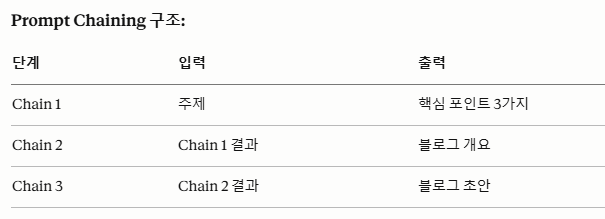

In [40]:
from openai import OpenAI

client = OpenAI()

topic = "인공지능이 취업 시장에 미치는 영향"

# Chain 1: 핵심 포인트 3가지 추출
print("=" * 50)
print("Chain 1: 핵심 포인트 추출")
print("=" * 50)

chain1 = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": f"다음 주제에 대한 핵심 포인트 3가지를 추출하세요:\n\n{topic}",
        }
    ],
    temperature=0,
    max_tokens=256,
)

key_points = chain1.choices[0].message.content
print(key_points)


# Chain 2: 핵심 포인트를 바탕으로 블로그 개요 작성
print("\n" + "=" * 50)
print("Chain 2: 블로그 개요 작성")
print("=" * 50)

chain2 = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                f"다음 핵심 포인트를 바탕으로:\n{key_points}\n\n"
                "서론, 본론, 결론을 포함한 블로그 게시물 개요를 작성하세요."
            ),
        }
    ],
    temperature=0,
    max_tokens=512,
)

outline = chain2.choices[0].message.content
print(outline)


# Chain 3: 개요를 바탕으로 블로그 초안 작성
print("\n" + "=" * 50)
print("Chain 3: 블로그 초안 작성")
print("=" * 50)

chain3 = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "user",
            "content": (
                f"다음 개요를 활용하여:\n{outline}\n\n"
                "흥미롭고 유익한 톤으로 짧은 블로그 게시물 초안을 작성하세요."
            ),
        }
    ],
    temperature=0.7,
    max_tokens=1024,
)

draft = chain3.choices[0].message.content
print(draft)

Chain 1: 핵심 포인트 추출
인공지능이 취업 시장에 미치는 영향에 대한 핵심 포인트 3가지는 다음과 같습니다:

1. **일자리 대체 및 변화**: 인공지능 기술의 발전으로 반복적이고 규칙적인 업무는 자동화되어 일부 직종이 사라질 위험이 있습니다. 그러나 동시에 새로운 직업군이 생겨나고, 기존 직업의 역할이 변화하여 인공지능과 협업하는 형태로 진화할 가능성이 큽니다.

2. **기술적 역량의 중요성 증가**: 인공지능이 다양한 산업에 도입됨에 따라, 데이터 분석, 프로그래밍, AI 관련 기술 등의 전문성이 요구됩니다. 이에 따라 취업 시장에서는 이러한 기술적 역량을 갖춘 인재에 대한 수요가 증가하고 있습니다.

3. **직업 교육 및 재교육 필요성**: 인공지능의 영향으로 직업 시장이 변화함에 따라, 기존 근로자와 구직자들은 새로운 기술을 배우고 적응해야 합니다. 따라서 기업과 정부는 직업 교육 및 재교육 프로그램을 강화하여 인력의 경쟁력을 높이는 것이 중요합니다.

Chain 2: 블로그 개요 작성
### 블로그 게시물 개요: 인공지능이 취업 시장에 미치는 영향

#### 서론
- 인공지능(AI)의 발전이 현대 사회에 미치는 영향 소개
- 취업 시장에서의 AI의 중요성 강조
- 본 글에서 다룰 핵심 포인트 소개: 일자리 대체 및 변화, 기술적 역량의 중요성 증가, 직업 교육 및 재교육 필요성

#### 본론
1. **일자리 대체 및 변화**
   - AI 기술의 발전으로 자동화되는 직무의 예시
   - 사라질 가능성이 있는 직종과 새로운 직업군의 등장
   - 인공지능과 협업하는 직업의 변화 양상
   - 사례 연구: 특정 산업에서의 AI 도입 효과

2. **기술적 역량의 중요성 증가**
   - AI 도입으로 인해 요구되는 기술적 역량의 변화
   - 데이터 분석, 프로그래밍, AI 관련 기술의 필요성
   - 기업들이 선호하는 인재상 변화
   - 통계 및 연구 결과: 기술적 역량이 취업에 미치는 영향

3. **직업 교육 및 재교육 필요성**
 

[일반 예제] 예제 : 영화 추천 → 이유 설명 → 최종 정리

In [41]:
from openai import OpenAI

client = OpenAI()

# Step 1 : 영화 추천
step1 = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 영화 추천 전문가입니다."
        },
        {
            "role": "user",
            "content": "감동적인 영화를 3편 추천해주세요."
        }
    ]
)

movies = step1.choices[0].message.content

print("=== Step 1 : 영화 추천 ===")
print(movies)

# Step 2 : 추천 이유 설명
step2 = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 영화 평론가입니다."
        },
        {
            "role": "user",
            "content": f"""
다음 영화들의 감동적인 이유를 설명해주세요.

영화 목록:
{movies}
"""
        }
    ]
)

movie_analysis = step2.choices[0].message.content

print("\n=== Step 2 : 영화 분석 ===")
print(movie_analysis)

# Step 3 : 최종 추천 정리
step3 = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 콘텐츠 요약 전문가입니다."
        },
        {
            "role": "user",
            "content": f"""
다음 내용을 짧게 최종 정리해주세요.

{movie_analysis}
"""
        }
    ]
)

final_result = step3.choices[0].message.content

print("\n=== Step 3 : 최종 정리 ===")
print(final_result)

=== Step 1 : 영화 추천 ===
감동적인 영화를 찾으신다면 다음 3편을 추천드립니다:

1. **'인생은 아름다워' (Life is Beautiful, 1997)**
   - 감독: 로베르토 베니니
   - 줄거리: 제2차 세계대전 당시 유대인 아버지가 아들과 함께 강제수용소 생활을 견뎌내며 아들에게 희망과 사랑을 전하는 이야기입니다.
   - 추천이유: 웃음과 눈물이 교차하는 감동적인 스토리가 마음을 울립니다.

2. **'쇼생크 탈출' (The Shawshank Redemption, 1994)**
   - 감독: 프랭크 다라본트
   - 줄거리: 억울하게 감옥에 수감된 남자의 자유와 희망을 향한 감동적인 여정을 그렸습니다.
   - 추천이유: 인간의 굴복하지 않는 의지와 우정의 힘을 느낄 수 있습니다.

3. **'포레스트 검프' (Forrest Gump, 1994)**
   - 감독: 로버트 저메키스
   - 줄거리: 순수한 마음을 지닌 포레스트 검프가 미국 현대사를 배경으로 펼치는 특별한 인생 이야기입니다.
   - 추천이유: 삶의 의미와 사랑, 우정을 따뜻하게 그려내어 큰 감동을 줍니다.

이 세 편 모두 깊은 감동과 여운을 남기는 명작이니 꼭 한 번 감상해 보시길 추천드립니다!

=== Step 2 : 영화 분석 ===
이 세 영화가 감동적인 이유는 각각의 독특한 스토리와 인물 간의 진심 어린 연결 고리에서 비롯됩니다.

1. **'인생은 아름다워'**는 비극적인 역사적 배경 속에서도 아버지의 무한한 사랑과 긍정적인 마인드가 절망을 희망으로 바꾸는 과정을 그립니다. 유머와 따뜻함을 잃지 않으면서도 가족애와 희생정신이 깊은 울림을 줍니다.

2. **'쇼생크 탈출'**은 절망적인 상황에서도 인간이 가진 불굴의 의지, 자유를 향한 갈망, 그리고 동료애가 얼마나 중요한지를 보여줍니다. 희망을 놓지 않는 주인공의 모습이 보는 이들에게 큰 힘과 영감을 줍니다.

3. **'포레스트 검프'**는 주인공의 순수함과 진심이 주변 사람들에게 긍정적인 영향을

# [실습] meta prompting

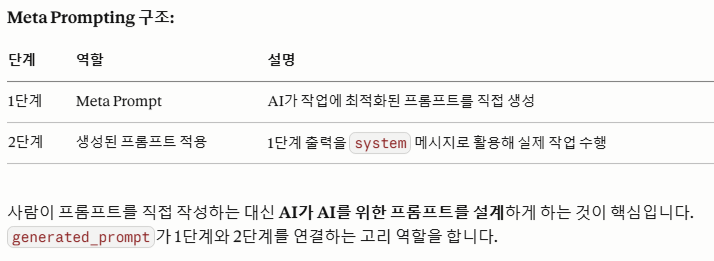

In [42]:
from openai import OpenAI

client = OpenAI()

task = "고객 리뷰를 분석하여 감성(긍정/부정/중립)을 분류하는 작업"

# Meta Prompt: 최적의 프롬프트 생성 요청
print("=" * 50)
print("Meta Prompt: 최적의 프롬프트 생성")
print("=" * 50)

meta = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "당신은 AI 프롬프트 전문가입니다. "
                "주어진 작업에 가장 효과적인 프롬프트를 설계하세요. "
                "설계한 프롬프트만 출력하고 부가 설명은 하지 마세요."
            ),
        },
        {
            "role": "user",
            "content": f"다음 작업을 위한 최적의 프롬프트를 작성해 주세요:\n\n{task}",
        },
    ],
    temperature=0.7,
    max_tokens=512,
)

generated_prompt = meta.choices[0].message.content
print(generated_prompt)


# 생성된 프롬프트로 실제 작업 수행
print("\n" + "=" * 50)
print("생성된 프롬프트로 실제 작업 수행")
print("=" * 50)

review = (
    "이 제품 정말 마음에 들어요! 배송도 빠르고 품질도 훌륭합니다. "
    "다만 가격이 조금 비싼 편이라 아쉽네요."
)

result = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": generated_prompt,  # 메타 프롬프트가 생성한 프롬프트 사용
        },
        {
            "role": "user",
            "content": f"다음 리뷰를 분석하세요:\n\n{review}",
        },
    ],
    temperature=0,
    max_tokens=512,
)

print(result.choices[0].message.content)

Meta Prompt: 최적의 프롬프트 생성
다음 고객 리뷰를 읽고 각 리뷰의 감성을 긍정, 부정, 중립 중 하나로 분류하십시오. 리뷰: "{고객 리뷰 내용을 여기에 입력하세요}"

생성된 프롬프트로 실제 작업 수행
이 리뷰는 긍정적인 감성을 가지고 있습니다. 제품에 대한 만족감과 빠른 배송, 훌륭한 품질을 언급하고 있지만, 가격이 비싸다는 아쉬움도 표현하고 있습니다. 전반적으로 긍정적인 요소가 더 강하므로 긍정으로 분류할 수 있습니다.


예제 : 여행 추천 Prompt 개선

In [43]:
from openai import OpenAI

client = OpenAI()

# Step 1 : Meta Prompting
meta_response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 Prompt Engineering 전문가입니다."
        },
        {
            "role": "user",
            "content": """
서울 여행 추천을 더 잘 받을 수 있는 Prompt를 작성해주세요.

조건:
- 가족 여행
- 어린 아이 포함
- 조용한 장소 선호
- 2박 3일 일정
"""
        }
    ]
)

optimized_prompt = meta_response.choices[0].message.content

print("=== 생성된 Prompt ===")
print(optimized_prompt)

# Step 2 : 생성된 Prompt 실제 사용
final_response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": "당신은 여행 전문가입니다."
        },
        {
            "role": "user",
            "content": optimized_prompt
        }
    ]
)

print("\n=== 최종 결과 ===")
print(final_response.choices[0].message.content)

=== 생성된 Prompt ===
서울에서 어린 아이를 동반한 가족이 조용하게 즐길 수 있는 2박 3일 여행 일정을 추천해 주세요. 가족 친화적인 장소 중 특히 소음이 적고 한적한 곳을 중심으로, 어린 아이가 안전하게 놀 수 있는 공간과 편안한 휴식처를 포함해 주시고, 이동 동선이 무겁지 않은 코스를 부탁드립니다. 날씨나 시즌에 따른 최적의 방문 시기도 함께 알려 주세요.

=== 최종 결과 ===
서울에서 어린 아이와 함께 조용하고 편안하게 즐길 수 있는 2박 3일 가족 여행 일정을 추천드립니다. 소음이 적고 안전한 공간 위주로 구성했으며, 이동 동선도 부담 없도록 설계했습니다.

---

### 최적 방문 시기
- 봄(4~6월) 또는 가을(9~11월)을 추천합니다. 날씨가 온화하고 미세먼지가 비교적 적어 야외 활동에 적합합니다.

---

### 1일차: 서울숲 & 성수동 근교

- **오전:**  
  - 서울숲 방문  
    서울숲은 넓고 녹음이 우거져 조용하며, 키즈존과 잔디밭, 산책로가 잘 조성되어 있어 아이가 안전하게 뛰어놀기 좋습니다. 사슴 생태원도 있어 아이가 동물과 교감할 수 있습니다.  
  - 산책 후 근처 카페에서 휴식 (성수동은 비교적 조용한 카페가 많음)

- **점심:** 성수동 내 가족 친화적 식당  
  - 오가닉 메뉴를 제공하는 곳 이나 한식당 추천

- **오후:** 한강 뚝섬지구  
  - 한강공원 내 뚝섬자전거공원 옆에는 어린이 놀이터가 있으며, 강변 산책로가 한적해 아이와 함께 산책하며 휴식 가능  
  - 간단한 간식과 물 준비 추천

- **숙박:** 뚝섬 또는 성수동 부근 조용한 호텔/게스트하우스

---

### 2일차: 북촌 한옥마을 & 삼청동 산책

- **오전:** 북촌 한옥마을  
  - 전통 한옥 사이 조용한 골목길 산책  
  - 아이 눈높이에 맞는 전통 체험 프로그램(예: 한지공예, 탈 만들기) 사전 예약 가능하면 좋음  
  - 북촌교육문화센터 내 어린이 공간 활용 가능

- **점심:** 삼청동